# Lab 6: Statistical Questions about the Data, Calclating the Significance of the Finding and the Confidence Interval and Such and So on and So Forth
Wednesday Nov 18

Phys 434 AB

Katherine Merrill

### Some Background:
The 2016 Munich Bell test (Rosenfeld et al.) entangles two single atoms in traps about 400 m apart. Entanglement is created by entanglement swapping, where each atom is first entangled with a photon, the two photons are interfered on a beam splitter, and a coincident photon detection heralds that the atoms are in an entangled Bell state, either $\Psi^+$ or $\Psi^-$. Each lab then picks a measurement setting at random (0 or 1) and records a result (0 or 1).
The csv files are strcutured so that one row = one heralded entangled pair, where each row has: the time of the event, which Bell state was announced, the setting and result in lab 1, the setting and result in lab 2, and the row numbers (line1, line2) of that event in the original lab files.

The measured correlation $S$ from the 2016 Munich Bell test is only a little above the bound 2, so the **statistical questions I hope to answer/explore in labs 6-8 are:** 
1. Is $S > 2$ a real effect or a fluctuation? (significance, $p$-value)
2. If it is real, what is $S$ and how uncertain is it? (confidence intervals)
3. What is the 5$\sigma$ threshold, and how does the answer change with a look-elsewhere (trials) factor?
4. How small a violation could this data set have detected? (sensitivity / limits)



## Data and imports: 

In [101]:
# 1. Load the data
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

data = pd.read_csv("Bell_2016-04-15_9_pairs.csv", sep="\t")
data.columns = ["time", "bell_state", "setting1", "result1",
                "setting2", "result2", "line1", "line2"]
lab1 = pd.read_csv("Bell_2016-04-15_9_lab_1.csv", sep=";")
lab2 = pd.read_csv("Bell_2016-04-15_9_lab_2.csv", sep=";")

print("events in pairs file:", len(data))

events in pairs file: 10201


## Cleaning the data:
The lab files have a column excluded from evaluation (yes/no). The flagged rows should not be used, so I'll remove them from the data files I'm going to use in this lab. 

I'll drop any pair from the data in which either lab 1 or lab 2 have the data excluded. So Ill use bad1.values[data["line1"]] for the flag of the lab 1 row each pair came from, bad2.values[data["line2"]] for lab 2, and then use `|` as a logical OR.


In [102]:
lab1.columns = [c.strip() for c in lab1.columns]
lab2.columns = [c.strip() for c in lab2.columns]
bad1 = lab1["excluded from evaluation"].str.strip() == "yes"
bad2 = lab2["excluded from evaluation"].str.strip() == "yes"

flagged = bad1.values[data["line1"]] | bad2.values[data["line2"]]
print("excluded rows in lab 1 file:", bad1.sum(), " lab 2 file:", bad2.sum())
print("pairs that are flagged as excluded:", flagged.sum())

data = data[~flagged]
print("events after cleaning:", len(data))

excluded rows in lab 1 file: 17  lab 2 file: 45
pairs that are flagged as excluded: 0
events after cleaning: 10201


## 3. Events vs time
This is the same plot that I had in lab 5, but I thought it would make sense to include it again anyway, except this time I am using time since first event in (hours) instead of miliseconds, as I think that makes more sense as a measure of time. This is the  cumulative count of events against time to check the data quality, you can see that a straight line means a steady event rate, (the atoms were being entangled and measured at a constant average rate), and flat stretches are downtime, such as the maintenance periods or breaks in the run, and the red ticks mark flagged lab 1 readings.

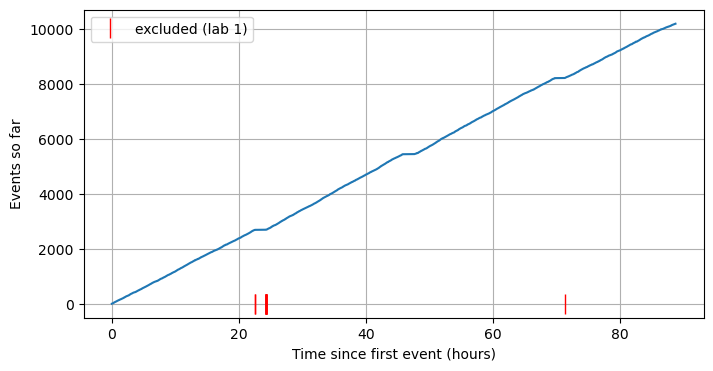

In [103]:
t0 = data["time"].iloc[0]
hours = (data["time"] - t0) / 3.6e6
t_bad = (lab1["time (Unix time in ms)"][bad1] - t0) / 3.6e6

plt.figure(figsize=(8, 4))
plt.plot(hours, np.arange(len(data)))
plt.plot(t_bad, np.zeros(len(t_bad)), "|", color="r", ms=14, label="excluded (lab 1)")
plt.xlabel("Time since first event (hours)")
plt.ylabel("Events so far")
plt.legend()
plt.grid(True)
plt.show()

## Correlations $E$
The correlation E is the average product of the two labs results: $$E = \frac{\text{agree - disagree}}{\text{total}}.$$. So its +1 if they agree and -1 id they disagree, and 0 if there is no correlation (that happens if the measuring detectors are oriented at 90 degrees to each other).

To calculate the correlation E (and eventually S), I'm making a 2 x 4 matrix of the E values, where the rows are Psi +, Psi -, and the columns refer to the 4 possible settings for lab 1 and lab 2: (0,0) (0,1) (1,0) (1,1). Then each combination of those gets its own E and N calculated (N is the number of events).

*(Not Important: When I first tried to do this, I got a TypeError because I tried to average the measurements of 1 or -1 as if the states were numbers. Psi + and Psi- are listed as strings "Psi+" and "Psi-" in the data set, not as the measurement outcomes 1 or -1, so its better to use logical operations to see if two states agree instead of multiplying them and seeing if its positive or negative. Just reminding myself so I dont do that agian.)*

## Uncertainty 
Each event contributes $+1$ or $-1$ with mean $E$, so the variance of one event is $1 - E^2$. The mean of $N$ independent events has variance
$$\sigma_E^2 = \frac{1-E^2}{N}, \qquad \sigma_E = \sqrt{\frac{1-E^2}{N}} .$$
*(Not Important: This means the binomial variance is smallest when $|E|$ is near 1.)*


In [111]:

# E = (number agree - number disagree) / total   
states = ["Psi+", "Psi-"]
E = np.zeros((2, 4))        # rows: Psi+, Psi-     columns: settings (0,0) (0,1) (1,0) (1,1)
N = np.zeros((2, 4))

for i in range(2):
    for s1 in [0, 1]:
        for s2 in [0, 1]:
            d = data[(data["bell_state"] == states[i]) &
                     (data["setting1"] == s1) & (data["setting2"] == s2)]
            agree = np.sum(d["result1"] == d["result2"])
            N[i, 2 * s1 + s2] = len(d)
            E[i, 2 * s1 + s2] = (agree - (len(d) - agree)) / len(d)

dE = np.sqrt((1 - E**2) / N) # binomial error
print("E =\n", E.round(3))
print("N =\n", N)

E =
 [[-0.53  -0.608 -0.596  0.463]
 [-0.513 -0.616  0.609 -0.508]]
N =
 [[1277. 1266. 1293. 1311.]
 [1313. 1256. 1249. 1236.]]


## 5. The CHSH value $S$
 $S= E(a,b)-E(a,b')+E(a',b) + E(a',b')\le2$ (The CHSH Inequality) is the inequality we are testing here. 
(Where a and a' are the detector settings on side A, b and b' are the detector settings on side B)

Out of the four correlations, only one of them needs to be subtracted, and which cell gets the minus sign depends on the measurement angles and the Bell state. To be quite honest, I can't really tell from the paper or from the data files which correlation is supposed to be the one that gets subtracted for this specific experiment, they don't talk about it in the paper. So to figure this out I am going to calculate S for all four measurement choices and choose whichever one gives the largest absolute value, since thats the one they should have chosen for the experiment.

Since the four cells are independent experiments, the error on S should be:
$\sigma_S^2 = \sum_n \sigma_{E_n}^2 .$

When I combine  $\Psi^+$ and $\Psi^-$, their average should be:
$\bar S = \frac{\sum_i S_i/\sigma_i^2}{\sum_i 1/\sigma_i^2}$, and the error should be $ \qquad \sigma_{\bar S} = \left(\sum_i \frac{1}{\sigma_i^2}\right)^{-1/2}$, since they are independent measurements on S even after they are summmed together.



In [113]:
import numpy as np

S = np.zeros((2, 4))   # stores all 4 sign combinations for both states
dS = np.zeros(2)

for i in range(2):
    for j in range(4):
        signs = np.ones(4)
        signs[j] = -1                      # flip the j-th term so that we can see what would happen if hmmm maybe that one is the negative one!
        S[i, j] = np.sum(signs * E[i])
        
    dS[i] = np.sqrt(np.sum(dE[i]**2))

# printing all 4 values for each state
state_names = ["Psi+", "Psi-"]
for i in range(2):
    print(f"All 4 S values for {state_names[i]}: {S[i].round(3)} +/- {dS[i]:.3f}")

S_tot = np.sum(S_best / dS**2) / np.sum(1 / dS**2)
dS_tot = 1 / np.sqrt(np.sum(1 / dS**2))
print(f"Combined S (best) = {S_tot:.3f} +/- {dS_tot:.3f}")
print(W[0])

All 4 S values for Psi+: [-0.211 -0.055 -0.079 -2.198] +/- 0.046
All 4 S values for Psi-: [-2.000e-03  2.050e-01 -2.246e+00 -1.100e-02] +/- 0.046
Combined S (best) = 2.222 +/- 0.033
[-1 -1 -1  1]


AHA! 
So we can see that the absolute value largest S is $|S(\Psi+, \Psi-)|=(2.198\pm 0.046, 2,246\pm 0.046)$

In [106]:
S_best = np.array([[2.198, 2.246]])
S_tot = np.sum(S_best / dS**2) / np.sum(1 / dS**2)
dS_tot = 1 / np.sqrt(np.sum(1 / dS**2))
print(f"Combined S (best) = {S_tot:.3f} +/- {dS_tot:.3f}")
print(f"{S_best[0,1]}")
E_abs = [abs(x) for x in E]
print(E_abs)


Combined S (best) = 2.222 +/- 0.033
2.246
[array([0.53014879, 0.60821485, 0.5962877 , 0.46300534]), array([0.51256664, 0.61624204, 0.60928743, 0.50809061])]


 Ok the data is verified. On to some plotting!

Plotting the correlations and $S$

First I'm plotting the  four  terms $|E_n|$ for each Bell state, which add up to $S$. I added dashed lines at 0.707 and 0.5 to show what the classical and quantum bounds are per term. (Since, if all four terms were equal, the classical model would need each to be less than 0.5 so that the sum is less than 2, and the quantum model would allow up to 0.707). This is just for reference, since only the whole sum is what is bound, so one term sitting above the dashed line is not a violation by itself.

I also plotted (on the right) $S$ with $1\sigma$ error bars for each state and the combination, against the classical bound $S=2$ and the quantum bound $2\sqrt2$. The measured values sit above 2 but well below $2\sqrt2$, because real experiments lose correlation to imperfect state preparation and detection.


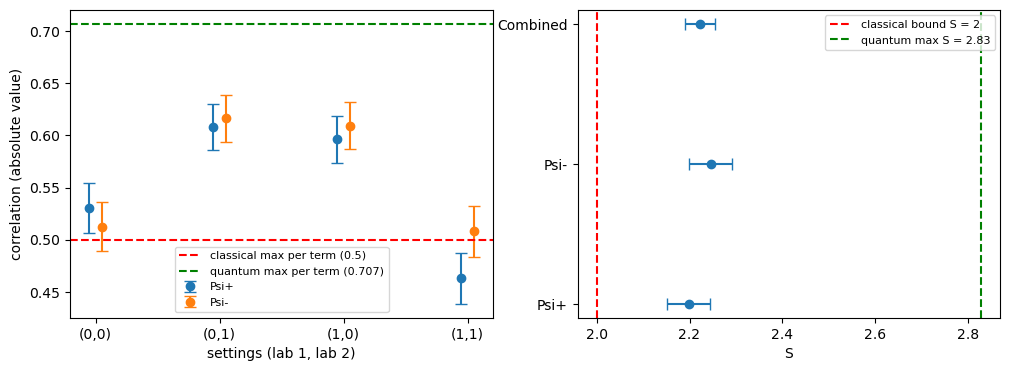

In [110]:
# Plotting the correlations and S
E_abs = [abs(x) for x in E] # making a new array, for plotting the absolute value of the correlations

labels = ["(0,0)", "(0,1)", "(1,0)", "(1,1)"]
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.errorbar(np.arange(4) - 0.05, E_abs[0], yerr=dE[0], fmt="o", capsize=4, label="Psi+")
plt.errorbar(np.arange(4) + 0.05, E_abs[1], yerr=dE[1], fmt="o", capsize=4, label="Psi-")
plt.axhline(0.5, color="r", ls="--", label="classical max per term (0.5)")
plt.axhline(np.sqrt(2) / 2, color="g", ls="--", label="quantum max per term (0.707)")
plt.xticks(range(4), labels)
plt.xlabel("settings (lab 1, lab 2)")
plt.ylabel("correlation (absolute value)")
plt.legend(fontsize=8)

plt.subplot(1, 2, 2)
plt.errorbar([S_best[0,0], S_best[0,1], S_tot], [0, 1, 2], xerr=[dS[0], dS[1], dS_tot], fmt="o", capsize=4)
plt.axvline(2, color="r", ls="--", label="classical bound S = 2")
plt.axvline(2 * np.sqrt(2), color="g", ls="--", label="quantum max S = 2.83")
plt.yticks([0, 1, 2], ["Psi+", "Psi-", "Combined"])
plt.xlabel("S")
plt.legend(fontsize=8)
plt.show()

This is where I shall leave off for lab 6! I have a lot more statistical questions to ask about the data, so my plan for labs 7 and 8 is to calculate the significance, p value, 5 sigma threshold, and take a look at the look-elsewhere effect. Calculating the p value particularly I think will be an interesting question because if I just assume that, due to the central limit theorem, the background can be approximated as a gaussian, then I can just use p = stats.norm.sf(z), especially since there are like 10k total events. But since the events are discrete, perhaps it would be more accurate to use poisson instead. But then I would need to figure out what the rate parameter is. So perhaps I can compare and contrast the two in the next lab. We shall see! 